# HOMEWORK 13

In this homework you are going to build your first classifier for the CIFAR-10 dataset. This dataset contains 10 different classes and you can learn more about it [here](https://www.cs.toronto.edu/~kriz/cifar.html). This homework consists of the following tasks:
* Dataset inspection
* Building the network
* Training
* Evaluation

At the end, as usual, there will be a couple of questions for you to answer :-)

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Dense, Flatten, Input, MaxPooling2D
from tensorflow.keras import Model
from time import time

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

# Set the seeds for reproducibility
from numpy.random import seed
from tensorflow.random import set_seed
seed_value = 1234578790
seed(seed_value)
set_seed(seed_value)

### Step 0: Dataset Inspection

Load the dataset and make a quick inspection.

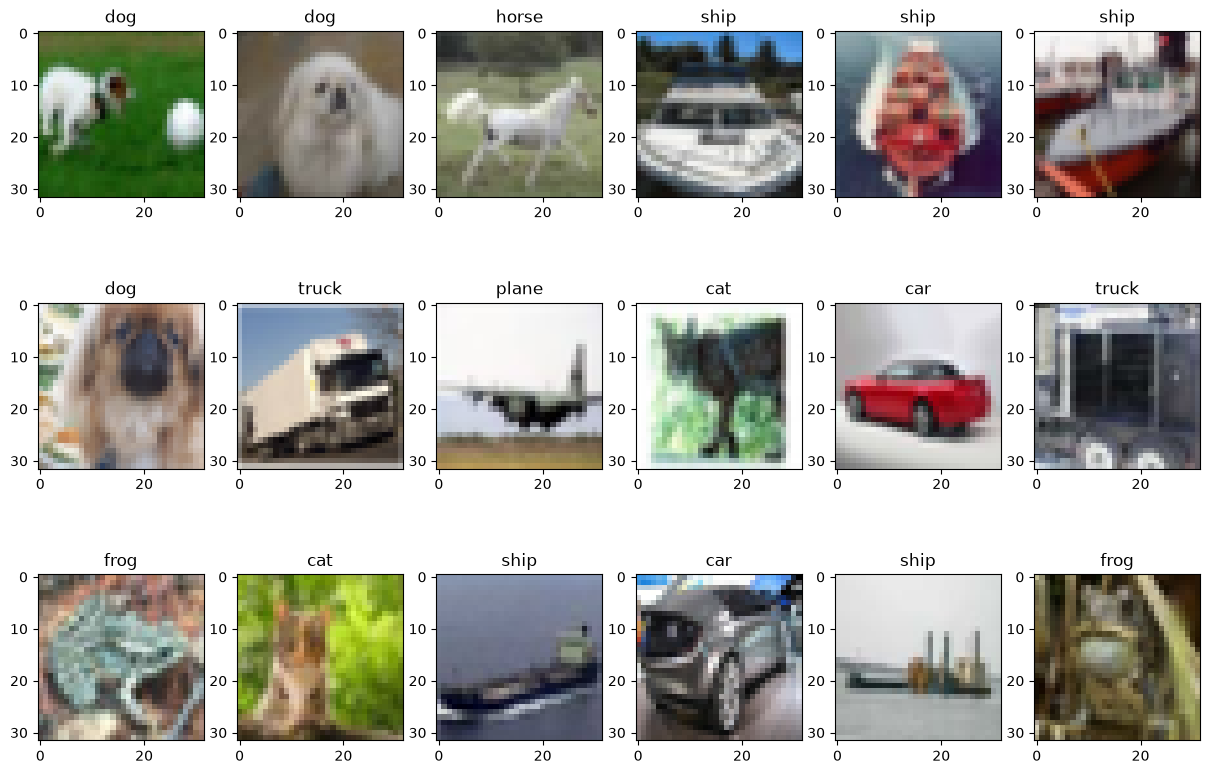

In [2]:
# Load the dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()
# Мітки мають форму (N, 1), робимо їх одновимірними (N,)
y_train = y_train.flatten()
y_test = y_test.flatten()
# Mapping from class ID to class name
classes = {0:'plane', 1:'car', 2:'bird', 3:'cat', 4:'deer',
           5:'dog', 6:'frog', 7:'horse', 8:'ship', 9:'truck'}

# Dataset params
num_classes = len(classes)
size = x_train.shape[1]

# Visualize random samples (as a plot with 3x6 samples)
for ii in range(18):    
    plt.subplot(3,6,ii+1)
    # Pick a random sample
    idx = np.random.randint(0, len(x_train))  # випадковий номер картинки
    # Show the image and the label
    plt.imshow(x_train[idx, ...])
    plt.title(classes[int(y_train[idx])])

Compute the class histogram (you can visualize it if you want). Is the dataset balanced?

Hint: You might find [Counter](https://docs.python.org/3/library/collections.html#collections.Counter) tool useful. In any case, it's up to you how you compute the histogram.

plane 5000
car 5000
bird 5000
cat 5000
deer 5000
dog 5000
frog 5000
horse 5000
ship 5000
truck 5000


(Text(0.5, 0, 'Class ID'), Text(0, 0.5, 'Counts'))

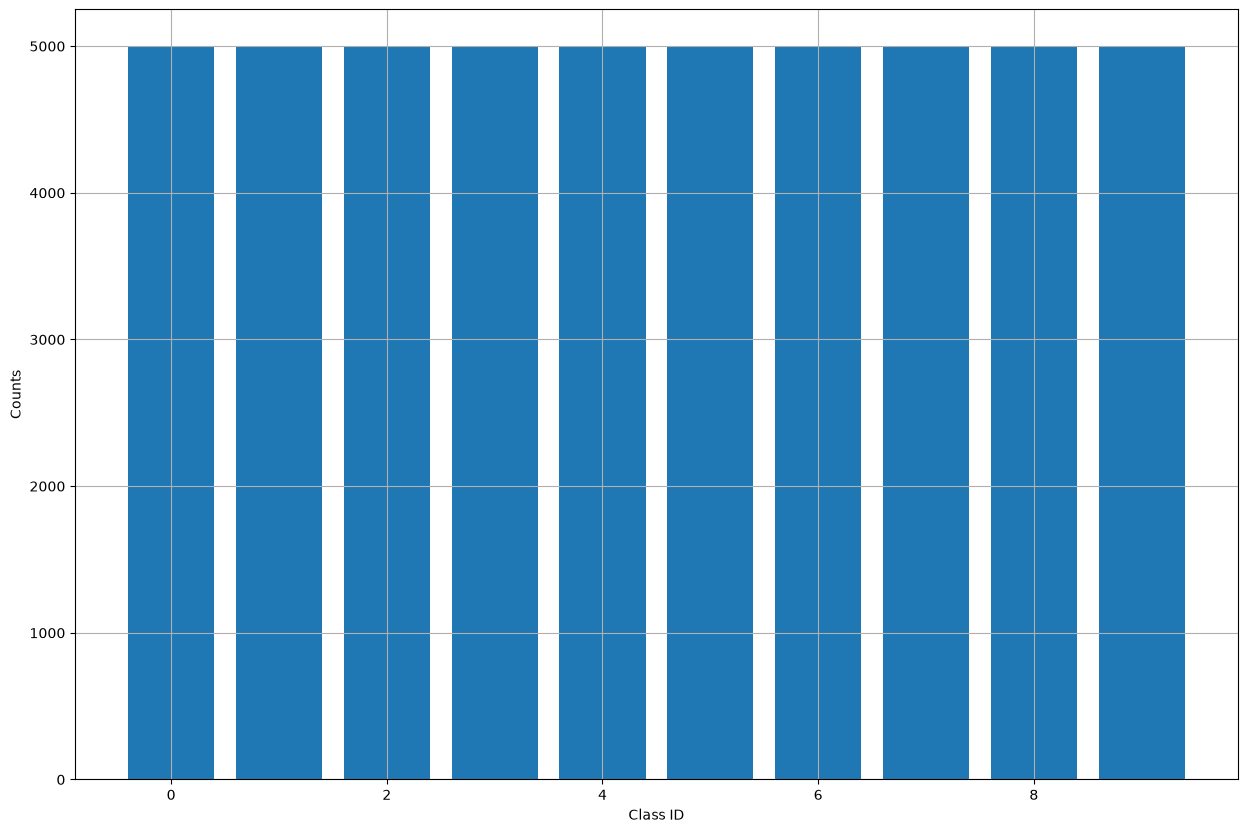

In [3]:
# Compute the class histogram
from collections import Counter
hist = Counter(y_train)  # скільки разів трапляється кожен клас

# Друкуємо кількість картинок для кожного класу
for class_id in range(num_classes):
    print(classes[class_id], hist[class_id])

plt.bar(hist.keys(), hist.values()), plt.grid(True)
plt.xlabel('Class ID'), plt.ylabel('Counts')

**Відповідь:** так, датасет збалансований: у кожному з 10 класів рівно 5000 тренувальних картинок.

### Step 1: Data Preparation

In this step, you'll need to prepare the data for training, i.e., you will have to normalize it and encode the labels as one-hot vectors.

In [4]:
# Normalization
x_train = x_train / 255  # пікселі з 0..255 у 0..1
x_test = x_test / 255

# One-hot encoding
y_train = tf.keras.utils.to_categorical(y_train, num_classes)  # 3 -> [0,0,0,1,0,0,0,0,0,0]
y_test = tf.keras.utils.to_categorical(y_test, num_classes)

print('Train set:   ', len(y_train), 'samples')
print('Test set:    ', len(y_test), 'samples')
print('Sample dims: ', x_train.shape)

Train set:    50000 samples
Test set:     10000 samples
Sample dims:  (50000, 32, 32, 3)


### Step 2: Building the Classifier

Build the CNN for CIFAR10 classification. For starters, you can use the same network we used in the lesson for the MNIST problem.

In [5]:
# Build the classifier
inputs = Input(shape=(size, size, 3))  # кольорова картинка 32x32, 3 канали (RGB)

net = Conv2D(16, kernel_size=(3, 3), activation="relu")(inputs)  # 16 фільтрів 3x3
net = MaxPooling2D(pool_size=(2, 2))(net)  # зменшуємо розмір удвічі
net = Conv2D(32, kernel_size=(3, 3), activation="relu")(net)  # 32 фільтри 3x3
net = MaxPooling2D(pool_size=(2, 2))(net)
net = Flatten()(net)  # карти ознак в один вектор
outputs = Dense(num_classes, activation="softmax")(net)  # 10 ймовірностей

model = Model(inputs, outputs)

# Show the model
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,618 (64.91 KB)

 Trainable params: 16,618 (64.91 KB)

 Non-trainable params: 0 (0.00 B)

### Step 3: Training

Compile the model and train it.

In [6]:
epochs = 25
batch_size = 128

# Compile the model
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# Train the model
start = time()
history = model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs,
                    validation_split=0.1, verbose=2)  # 10% даних на валідацію
print('Elapsed time', time() - start)

Epoch 1/25
352/352 - 3s - 7ms/step - accuracy: 0.3799 - loss: 1.7419 - val_accuracy: 0.4534 - val_loss: 1.5733
Epoch 2/25
352/352 - 2s - 6ms/step - accuracy: 0.5025 - loss: 1.4178 - val_accuracy: 0.4986 - val_loss: 1.4384
Epoch 3/25
352/352 - 2s - 6ms/step - accuracy: 0.5480 - loss: 1.3028 - val_accuracy: 0.5426 - val_loss: 1.3091
Epoch 4/25
352/352 - 2s - 6ms/step - accuracy: 0.5743 - loss: 1.2304 - val_accuracy: 0.5738 - val_loss: 1.2235
Epoch 5/25
352/352 - 2s - 6ms/step - accuracy: 0.5910 - loss: 1.1789 - val_accuracy: 0.5900 - val_loss: 1.1787
Epoch 6/25
352/352 - 2s - 6ms/step - accuracy: 0.6055 - loss: 1.1399 - val_accuracy: 0.6024 - val_loss: 1.1457
Epoch 7/25
352/352 - 2s - 6ms/step - accuracy: 0.6141 - loss: 1.1084 - val_accuracy: 0.6148 - val_loss: 1.1191
Epoch 8/25
352/352 - 2s - 6ms/step - accuracy: 0.6241 - loss: 1.0814 - val_accuracy: 0.6222 - val_loss: 1.0970
Epoch 9/25
352/352 - 2s - 6ms/step - accuracy: 0.6320 - loss: 1.0577 - val_accuracy: 0.6270 - val_loss: 1.0804
E

Train Acc      0.7064666748046875
Validation Acc 0.6776000261306763


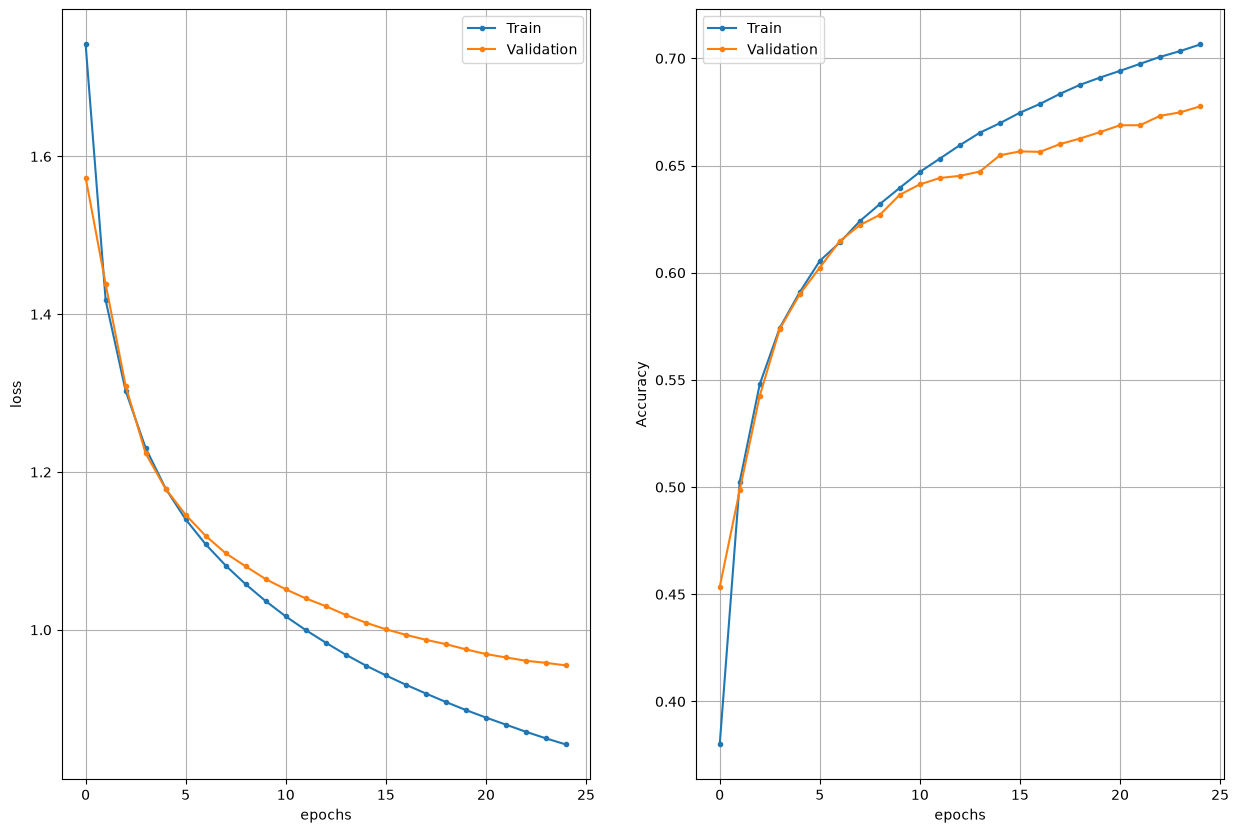

In [7]:
# Show training history (this cell is complete, nothing to implement here :-) )
h = history.history
epochs = range(len(h['loss']))

plt.subplot(121), plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
plt.legend(['Train', 'Validation'])
plt.subplot(122), plt.plot(epochs, h['accuracy'], '.-',
                           epochs, h['val_accuracy'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

print('Train Acc     ', h['accuracy'][-1])
print('Validation Acc', h['val_accuracy'][-1])    

### Step 4: Evaluation

In this step, you have to calculate the accuracies and visualize some random samples. For the evaluation, you are going to use the test split from the dataset.

In [8]:
# Compute the labels and the predictions as sparse values
y_true = np.argmax(y_test, axis=1)  # one-hot -> номер класу
y_pred = np.argmax(model.predict(x_test), axis=1)  # клас з найбільшою ймовірністю

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 717us/step


In [9]:
# Compute and print the accuracy for each class
for class_id, class_name in classes.items():
    mask = y_true == class_id  # лише картинки цього класу
    acc = np.sum(y_pred[mask] == class_id) / np.sum(mask)  # частка вгаданих
    print(class_name, acc)

plane 0.694
car 0.84
bird 0.475
cat 0.391
deer 0.748
dog 0.622
frog 0.769
horse 0.706
ship 0.668
truck 0.712


In [10]:
# Print the overall stats
ev = model.evaluate(x_test, y_test)
print('Test loss  ', ev[0])
print('Test metric', ev[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 742us/step - accuracy: 0.6625 - loss: 0.9819
Test loss   0.9818650484085083
Test metric 0.6625000238418579


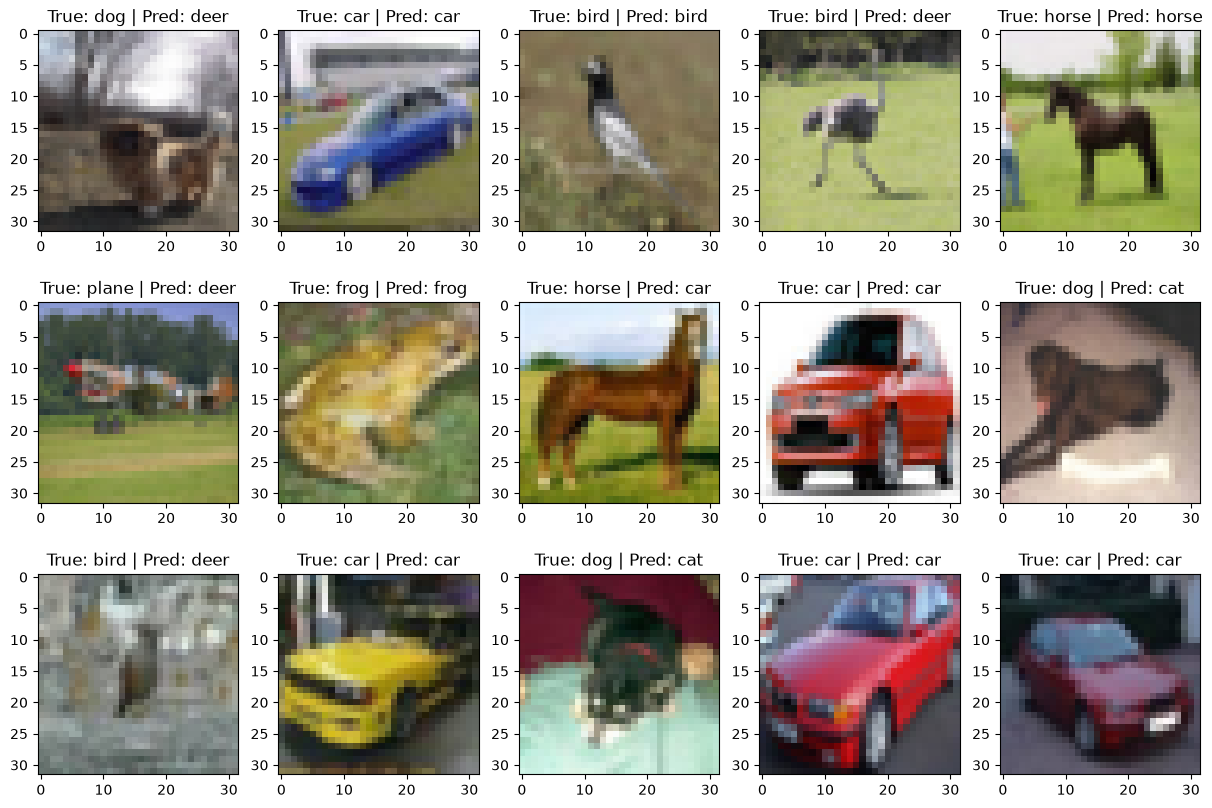

In [11]:
# Show random samples
for ii in range(15):
    # Pick a random sample
    idx = np.random.randint(0, len(x_test))  # випадкова картинка з тестового набору
    # Show the results
    plt.subplot(3,5,ii+1), plt.imshow(x_test[idx, ...])
    plt.title('True: ' + str(classes[y_true[idx]]) + ' | Pred: ' + str(classes[y_pred[idx]]))

### Questions
* What is the overall accuracy of the classifier?
* What modifications would you do in order to improve the classification accuracy?
* Make **one** modification (that you think can help) and train the classifier again. Does the accuracy improve?

### Модифікація: більше фільтрів (32 і 64 замість 16 і 32)

In [12]:
# Та сама мережа, але вдвічі більше фільтрів у кожному Conv2D
inputs = Input(shape=(size, size, 3))

net = Conv2D(32, kernel_size=(3, 3), activation="relu")(inputs)  # 32 фільтри замість 16
net = MaxPooling2D(pool_size=(2, 2))(net)
net = Conv2D(64, kernel_size=(3, 3), activation="relu")(net)  # 64 фільтри замість 32
net = MaxPooling2D(pool_size=(2, 2))(net)
net = Flatten()(net)
outputs = Dense(num_classes, activation="softmax")(net)

model2 = Model(inputs, outputs)
model2.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │        23,050 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 42,442 (165.79 KB)

 Trainable params: 42,442 (165.79 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
epochs = 25  # знову число, бо вище epochs перетворили на range
batch_size = 128

model2.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

start = time()
history2 = model2.fit(x_train, y_train, batch_size=batch_size, epochs=epochs,
                      validation_split=0.1, verbose=2)
print('Elapsed time', time() - start)

Epoch 1/25
352/352 - 5s - 13ms/step - accuracy: 0.4044 - loss: 1.6710 - val_accuracy: 0.4740 - val_loss: 1.5297
Epoch 2/25
352/352 - 4s - 12ms/step - accuracy: 0.5331 - loss: 1.3346 - val_accuracy: 0.5334 - val_loss: 1.3400
Epoch 3/25
352/352 - 4s - 12ms/step - accuracy: 0.5812 - loss: 1.2048 - val_accuracy: 0.5938 - val_loss: 1.1782
Epoch 4/25
352/352 - 4s - 12ms/step - accuracy: 0.6109 - loss: 1.1218 - val_accuracy: 0.6200 - val_loss: 1.0993
Epoch 5/25
352/352 - 4s - 12ms/step - accuracy: 0.6321 - loss: 1.0621 - val_accuracy: 0.6400 - val_loss: 1.0512
Epoch 6/25
352/352 - 4s - 12ms/step - accuracy: 0.6502 - loss: 1.0154 - val_accuracy: 0.6506 - val_loss: 1.0194
Epoch 7/25
352/352 - 4s - 12ms/step - accuracy: 0.6642 - loss: 0.9778 - val_accuracy: 0.6564 - val_loss: 0.9973
Epoch 8/25
352/352 - 4s - 12ms/step - accuracy: 0.6737 - loss: 0.9467 - val_accuracy: 0.6644 - val_loss: 0.9831
Epoch 9/25
352/352 - 4s - 12ms/step - accuracy: 0.6840 - loss: 0.9205 - val_accuracy: 0.6708 - val_loss:

Train Acc      0.7682444453239441
Validation Acc 0.6869999766349792


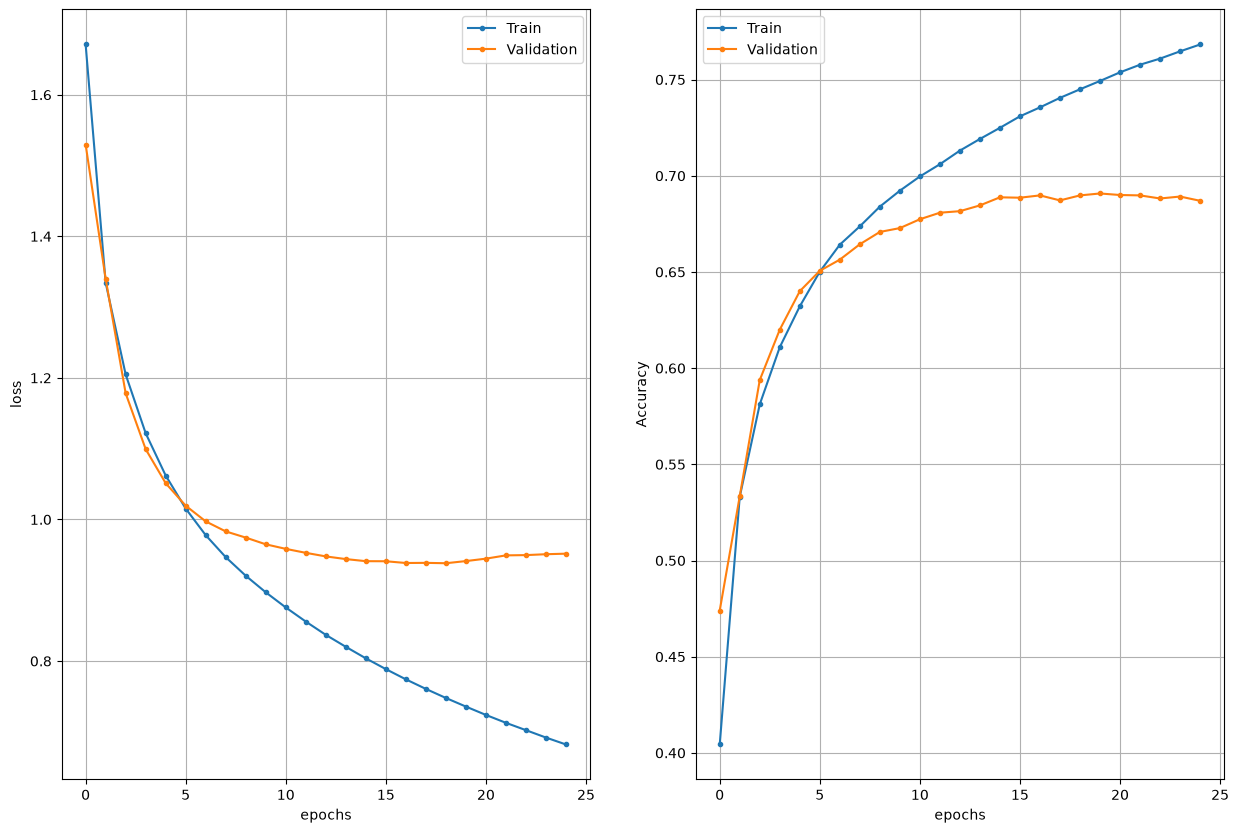

In [14]:
# Графіки навчання другої мережі
h2 = history2.history
epochs = range(len(h2['loss']))

plt.subplot(121), plt.plot(epochs, h2['loss'], '.-', epochs, h2['val_loss'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('loss')
plt.legend(['Train', 'Validation'])
plt.subplot(122), plt.plot(epochs, h2['accuracy'], '.-',
                           epochs, h2['val_accuracy'], '.-')
plt.grid(True), plt.xlabel('epochs'), plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

print('Train Acc     ', h2['accuracy'][-1])
print('Validation Acc', h2['val_accuracy'][-1])

In [15]:
# Точність по класах для другої мережі
y_pred2 = np.argmax(model2.predict(x_test), axis=1)

for class_id, class_name in classes.items():
    mask = y_true == class_id
    acc = np.sum(y_pred2[mask] == class_id) / np.sum(mask)
    print(class_name, acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
plane 0.704
car 0.801
bird 0.516
cat 0.395
deer 0.704
dog 0.631
frog 0.862
horse 0.735
ship 0.643
truck 0.817


In [16]:
# Порівняння двох мереж на тестовому наборі
ev2 = model2.evaluate(x_test, y_test)
print('Мережа 1 (16/32): test loss', ev[0], 'test acc', ev[1])
print('Мережа 2 (32/64): test loss', ev2[0], 'test acc', ev2[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6808 - loss: 0.9846
Мережа 1 (16/32): test loss 0.9818650484085083 test acc 0.6625000238418579
Мережа 2 (32/64): test loss 0.984619140625 test acc 0.6808000206947327


### Questions
* What is the overall accuracy of the classifier?
Близько 66% на тестових даних (test accuracy ≈ 0.66).
* What modifications would you do in order to improve the classification accuracy?
більше фільтрів у Conv2D і більше шарів Conv2D + MaxPooling
* Make **one** modification (that you think can help) and train the classifier again. Does the accuracy improve?
Подвоїв кількість фільтрів: 32 і 64 замість 16 і 32. Точність на тесті зросла з ≈66% до ≈68%. Але різниця між train (≈77%) і validation (≈69%) стала більшою.